# Term Project 2: Conditional Latent Diffusion with StyleGAN2
**MATH 482: Probabilistic Approach to Machine Learning** (Fall 2025)  
**Group Members:** Toprak Özdemir & Hüseyin Çiyik

In Project 1, we explored linear manipulation in the latent space of StyleGAN2 ($\mathcal{W}$-space) to edit facial attributes. While effective for simple edits, linear interpolation assumes a flat data manifold, which can lead to unnatural distortions when traversing "empty" regions of the latent space.

In this project, we implement a **Conditional Latent Diffusion Model (LDM)**. Unlike linear interpolation, this probabilistic approach learns the distribution of valid latent vectors. By training a diffusion model directly on the $\mathcal{W}$-space vectors, we can perform controlled, non-linear edits (such as adding eyeglasses) while ensuring the modified vector remains on the manifold of realistic faces.

# Section 1 — Environment Setup

In [2]:
import sys
import os
import torch
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

!pip install ninja

if not os.path.exists('stylegan2-ada-pytorch'):
    !git clone https://github.com/NVlabs/stylegan2-ada-pytorch.git

sys.path.insert(0, "./stylegan2-ada-pytorch")

print(f"PyTorch Version: {torch.__version__}")
print(f"CUDA Available: {torch.cuda.is_available()}")

if torch.cuda.is_available():
    device_id = torch.cuda.current_device()
    gpu_name = torch.cuda.get_device_name(device_id)
    major, minor = torch.cuda.get_device_capability(device_id)
    
    print(f"Device Name: {gpu_name}")
    print(f"Compute Capability: {major}.{minor}")
    
    os.environ['TORCH_CUDA_ARCH_LIST'] = f"{major}.{minor}"
else:
    raise RuntimeError("GPU not detected.")

PyTorch Version: 2.8.0+cu126
CUDA Available: True
Device Name: Tesla T4
Compute Capability: 7.5
Set TORCH_CUDA_ARCH_LIST to 7.5 (Suppressing architecture warnings)


# Section 2 — Load Pretrained StyleGAN2 Generator

In [3]:
import dnnlib
import legacy
import pickle

url = 'https://nvlabs-fi-cdn.nvidia.com/stylegan2-ada-pytorch/pretrained/ffhq.pkl'
file_name = 'ffhq.pkl'

if not os.path.exists(file_name):
    print(f"Downloading {file_name}...")
    !wget -q -O $file_name $url
else:
    print(f"Found {file_name} locally. Skipping download.")

print(f'Loading networks from "{file_name}"...')
device = torch.device('cuda')

with open(file_name, 'rb') as f:
    G_ema = legacy.load_network_pkl(f)['G_ema'].to(device)

G_ema.eval()
print("Generator loaded successfully.")

Found ffhq.pkl locally. Skipping download.
Loading networks from "ffhq.pkl"...
Generator loaded successfully.


# Section 3 — Attribute Classifier
We use a subset of CelebA (20,000 samples) to train the classifier and 2,000 unseen samples for validation.

In [4]:
import torch.nn as nn
import torch.optim as optim
import torchvision.models as models
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, Dataset, random_split, TensorDataset
from PIL import Image
import pandas as pd
import numpy as np

TARGET_ATTR_IDX = 15   # 15: Eyeglasses
ATTR_NAME = "Eyeglasses"
MODEL_PATH = f"classifier_resnet18_attr{TARGET_ATTR_IDX}.pth"
TRAIN_SIZE = 20000
TEST_SIZE = 2000
BATCH_SIZE = 64

classifier = models.resnet18(weights='DEFAULT')
classifier.fc = nn.Linear(classifier.fc.in_features, 1)
classifier = classifier.to(device)

class CelebAKaggle(Dataset):
    def __init__(self, root_dir, transform=None):
        self.root_dir = root_dir
        self.transform = transform
        self.attr_df = pd.read_csv(os.path.join(root_dir, 'list_attr_celeba.csv'))
        self.img_dir = os.path.join(root_dir, 'img_align_celeba', 'img_align_celeba')
        self.attrs = (self.attr_df.iloc[:, 1:].values + 1) // 2
        self.filenames = self.attr_df.iloc[:, 0].values
        
    def __len__(self):
        return len(self.attr_df)
    
    def __getitem__(self, idx):
        path = os.path.join(self.img_dir, self.filenames[idx])
        image = Image.open(path).convert('RGB')
        if self.transform:
            image = self.transform(image)
        return image, torch.tensor(self.attrs[idx]).long()

kaggle_path = '/kaggle/input/celeba-dataset'
if not os.path.exists(kaggle_path):
    raise FileNotFoundError("CelebA dataset not found.")

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

print("Loading CelebA dataset...")
full_dataset = CelebAKaggle(root_dir=kaggle_path, transform=transform)

unused_size = len(full_dataset) - TRAIN_SIZE - TEST_SIZE
train_subset, test_subset, _ = random_split(
    full_dataset, 
    [TRAIN_SIZE, TEST_SIZE, unused_size],
    generator=torch.Generator().manual_seed(168)
)

train_loader = DataLoader(train_subset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
test_loader = DataLoader(test_subset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f"Data Split Created: {len(train_subset)} Train, {len(test_subset)} Test images.")

if os.path.exists(MODEL_PATH):
    print(f"Found saved model: '{MODEL_PATH}'. Loading weights...")
    classifier.load_state_dict(torch.load(MODEL_PATH, map_location=device))
else:
    print(f"Training classifier for attribute '{ATTR_NAME}'...")
    criterion = nn.BCEWithLogitsLoss()
    optimizer = optim.Adam(classifier.parameters(), lr=0.001)
    classifier.train()
    
    for i, (inputs, targets) in enumerate(tqdm(train_loader, desc="Training Epoch 1")):
        inputs = inputs.to(device)
        labels = targets[:, TARGET_ATTR_IDX].float().unsqueeze(1).to(device)
        
        optimizer.zero_grad()
        outputs = classifier(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
    print("Training complete. Saving model...")
    torch.save(classifier.state_dict(), MODEL_PATH)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 191MB/s]


Loading CelebA dataset...
Data Split Created: 20000 Train, 2000 Test images.
Found saved model: 'classifier_resnet18_attr15.pth'. Loading weights...


Evaluate the accuracy of the classifier on the test subset.

In [5]:
print(f"Validating model on {len(test_subset)} unseen test images...")
classifier.eval()
correct = 0
total = 0

with torch.no_grad():
    for inputs, targets in tqdm(test_loader, desc="Testing"):
        inputs = inputs.to(device)
        labels = targets[:, TARGET_ATTR_IDX].float().unsqueeze(1).to(device)
        
        outputs = classifier(inputs)
        predicted = (torch.sigmoid(outputs) > 0.5).float()
        
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total
print(f"Final Test Accuracy for '{ATTR_NAME}': {accuracy:.2f}%")

Validating model on 2000 unseen test images...


Testing: 100%|██████████| 32/32 [00:11<00:00,  2.90it/s]


Final Test Accuracy for 'Eyeglasses': 99.45%
Model is ready for Latent Diffusion data labeling.


# Section 4 — Latent Space Dataset Preparation

In [6]:
import numpy as np
import torch
from torch.utils.data import TensorDataset, DataLoader
from tqdm import tqdm
import os
import random

NUM_SAMPLES = 20000
BATCH_SIZE = 32
INPUT_PATH = f"/kaggle/input/project2-latent-data15/latent_dataset{TARGET_ATTR_IDX}.npz"
DATASET_PATH = f"latent_dataset{TARGET_ATTR_IDX}.npz"
STATS_PATH = f"data_stats{TARGET_ATTR_IDX}.pt"

resize_normalize = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

if os.path.exists(INPUT_PATH):
    print(f"Loading dataset from: {INPUT_PATH}")
    data = np.load(INPUT_PATH)
    W_np = data['w']
    L_np = data['labels']
    print(f"Loaded {len(W_np)} raw samples.")
elif os.path.exists(DATASET_PATH):
    print(f"Loading raw dataset from '{DATASET_PATH}'...")
    data = np.load(DATASET_PATH)
    W_np = data['w']
    L_np = data['labels']
    print(f"Loaded {len(W_np)} raw samples.")
else:
    print(f"Generating {NUM_SAMPLES} samples...")
    w_dataset = []
    labels_dataset = []

    with torch.no_grad():
        for i in tqdm(range(0, NUM_SAMPLES, BATCH_SIZE)):
            current_batch = min(BATCH_SIZE, NUM_SAMPLES - i)
            
            z = torch.randn([current_batch, G_ema.z_dim]).to(device)
            w = G_ema.mapping(z, None)
            img_gen = G_ema.synthesis(w, noise_mode='const')
            
            img_input = (img_gen * 0.5 + 0.5).clamp(0, 1)
            img_input = resize_normalize(img_input)
            
            logits = classifier(img_input)
            probs = torch.sigmoid(logits)
            preds = (probs > 0.5).float().cpu().numpy()
            
            w_flat = w[:, 0, :].cpu().numpy()
            w_dataset.append(w_flat)
            labels_dataset.append(preds)

    W_np = np.concatenate(w_dataset, axis=0)
    L_np = np.concatenate(labels_dataset, axis=0)
    np.savez(DATASET_PATH, w=W_np, labels=L_np)
    print(f"Raw dataset saved to '{DATASET_PATH}'")

# Normalize W vectors using dataset mean and standard deviation
W_tensor_raw = torch.tensor(W_np, dtype=torch.float32)
L_data = torch.tensor(L_np, dtype=torch.float32)

train_mean = W_tensor_raw.mean(dim=0)
train_std = W_tensor_raw.std(dim=0)

torch.save({'mean': train_mean, 'std': train_std}, STATS_PATH)
print(f"Statistics saved to '{STATS_PATH}'")

W_norm = (W_tensor_raw - train_mean) / (train_std + 1e-8)

print(f"Original Data: Mean={W_tensor_raw.mean().item():.2f}, Std={W_tensor_raw.std().item():.2f}")
print(f"Normalized Data: Mean={W_norm.mean().item():.2f}, Std={W_norm.std().item():.2f}")

def seed_everything(seed):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

SEED = 198
seed_everything(SEED)

g = torch.Generator()
g.manual_seed(SEED)

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

train_ds = TensorDataset(W_norm, L_data)
train_loader = DataLoader(
    train_ds, 
    batch_size=64, 
    shuffle=True,
    worker_init_fn=seed_worker,
    generator=g
)

print(f"Reproducible (seed={SEED}) DataLoader ready with {len(train_ds)} samples.")
print(f"Positive Samples ({ATTR_NAME}): {L_data.sum().item()}")

 Loading dataset from Kaggle Input: /kaggle/input/project2-latent-data15/latent_dataset15.npz
Loaded 20000 raw samples.
Computing dataset statistics for Normalization...
Statistics saved to 'data_stats15.pt'
Original Data: Mean=0.10, Std=0.47
Normalized Data: Mean=-0.00, Std=1.00
Reproducible (seed =198) DataLoader ready with 20000 samples.
Positive Samples (Eyeglasses): 3444.0


# Section 5 — Conditional Latent Diffusion Model

In [7]:
import math

class SinusoidalPositionEmbeddings(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, time):
        device = time.device
        half_dim = self.dim // 2
        embeddings = math.log(10000) / (half_dim - 1)
        embeddings = torch.exp(torch.arange(half_dim, device=device) * -embeddings)
        embeddings = time[:, None] * embeddings[None, :]
        embeddings = torch.cat((embeddings.sin(), embeddings.cos()), dim=-1)
        return embeddings

class AdvancedLatentDiffusion(nn.Module):
    def __init__(self, w_dim=512, time_dim=256, num_classes=2, hidden_dim=1024): 
        super().__init__()
        
        self.time_mlp = nn.Sequential(
            SinusoidalPositionEmbeddings(time_dim),
            nn.Linear(time_dim, time_dim),
            nn.GELU(),
            nn.Linear(time_dim, time_dim)
        )
        
        # 0: No Glasses, 1: Glasses, 2: Null token (unconditional)
        self.cond_emb = nn.Embedding(num_classes + 1, time_dim)
        self.input_proj = nn.Linear(w_dim, hidden_dim)
        
        self.blocks = nn.ModuleList([
            self._make_block(hidden_dim, time_dim),
            self._make_block(hidden_dim, time_dim),
            self._make_block(hidden_dim, time_dim),
            self._make_block(hidden_dim, time_dim),
            self._make_block(hidden_dim, time_dim)
        ])
        
        self.output_proj = nn.Sequential(
            nn.LayerNorm(hidden_dim),
            nn.Linear(hidden_dim, w_dim)
        )

    def _make_block(self, hidden_dim, time_dim):
        return nn.Sequential(
            nn.Linear(hidden_dim + time_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.GELU(),
            nn.Dropout(0.1), 
            nn.Linear(hidden_dim, hidden_dim),
            nn.LayerNorm(hidden_dim) 
        )

    def forward(self, x, t, c):
        t_emb = self.time_mlp(t)            
        c_emb = self.cond_emb(c)            
        ctx = t_emb + c_emb
        
        h = self.input_proj(x)
        
        for block in self.blocks:
            h_input = torch.cat([h, ctx], dim=1) 
            h_out = block(h_input)
            h = h + h_out
        
        return self.output_proj(h)

model = AdvancedLatentDiffusion().to(device)
print("Diffusion model initialized.")

 Advanced Diffusion Model initialized.


In [8]:
import torch.optim as optim

DIFFUSION_INPUT_PATH = f"/kaggle/input/project2-latent-diffusion15/latent_diffusion_final{TARGET_ATTR_IDX}.pth"
DIFFUSION_MODEL_PATH = f"latent_diffusion_final{TARGET_ATTR_IDX}.pth"

TIMESTEPS = 1000
beta = torch.linspace(1e-4, 0.02, TIMESTEPS).to(device)
alpha = 1.0 - beta
alpha_bar = torch.cumprod(alpha, dim=0)

if os.path.exists(DIFFUSION_INPUT_PATH):
    print(f"Loading trained model from input: '{DIFFUSION_INPUT_PATH}'...")
    model.load_state_dict(torch.load(DIFFUSION_INPUT_PATH, map_location=device))
    model.eval()
elif os.path.exists(DIFFUSION_MODEL_PATH):
    print(f"Loading trained model from '{DIFFUSION_MODEL_PATH}'...")
    model.load_state_dict(torch.load(DIFFUSION_MODEL_PATH, map_location=device))
    model.eval()
else:
    print("Starting diffusion training...")
    
    EPOCHS = 100
    LR = 1e-4
    CFG_DROPOUT_PROB = 0.1
    NULL_TOKEN = 2
    
    optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-5)
    loss_fn = nn.MSELoss()
    
    model.train()
    
    for epoch in range(EPOCHS):
        pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS}", leave=False)
        loss_hist = []
        
        for w_batch, c_batch in pbar:
            w_batch = w_batch.to(device)
            c_batch = c_batch.to(device).long().squeeze() 
            curr_batch_size = w_batch.shape[0]
            
            t = torch.randint(0, TIMESTEPS, (curr_batch_size,), device=device).long()
            noise = torch.randn_like(w_batch)
            a_bar = alpha_bar[t].unsqueeze(1)
            w_noisy = torch.sqrt(a_bar) * w_batch + torch.sqrt(1 - a_bar) * noise
            
            mask_prob = torch.rand(curr_batch_size, device=device)
            drop_mask = mask_prob < CFG_DROPOUT_PROB
            
            c_input = c_batch.clone()
            c_input[drop_mask] = NULL_TOKEN
                
            noise_pred = model(w_noisy, t, c_input)
            loss = loss_fn(noise_pred, noise)
            
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            
            loss_hist.append(loss.item())
            pbar.set_postfix({'loss': np.mean(loss_hist)})
            
    torch.save(model.state_dict(), DIFFUSION_MODEL_PATH)
    print(f"Training complete. Model saved to '{DIFFUSION_MODEL_PATH}'")

Loading trained model from 'latent_diffusion_final15.pth'...


# Section 6 — SDE-Edit (Manipulation)

In [9]:
import torch

if os.path.exists(STATS_PATH):
    stats = torch.load(STATS_PATH)
    DATA_MEAN = stats['mean'].to(device)
    DATA_STD = stats['std'].to(device)
else:
    print("Warning: Stats file not found. Using identity normalization.")
    DATA_MEAN = torch.zeros(512).to(device)
    DATA_STD = torch.ones(512).to(device)

def extract(a, t, x_shape):
    if a.device != t.device:
        a = a.to(t.device)
    batch_size = t.shape[0]
    out = a.gather(-1, t)
    return out.reshape(batch_size, *((1,) * (len(x_shape) - 1)))

@torch.no_grad()
def sde_edit(w_source, target_label, start_step, guidance_scale=3.0):
    model.eval()
    
    # Normalize input latent vector
    w_norm = (w_source - DATA_MEAN) / (DATA_STD + 1e-8)

    # Forward diffusion up to start_step
    t_start_tensor = torch.full((w_norm.shape[0],), start_step, device=device, dtype=torch.long)
    noise = torch.randn_like(w_norm)
    a_bar = extract(alpha_bar, t_start_tensor, w_norm.shape)
    w_t = torch.sqrt(a_bar) * w_norm + torch.sqrt(1 - a_bar) * noise
    
    # Reverse denoising process
    timesteps = list(range(0, start_step))[::-1]
    
    for i, t_step in enumerate(timesteps):
        t_tensor = torch.full((w_norm.shape[0],), t_step, device=device, dtype=torch.long)
        
        bs = w_norm.shape[0]
        cond_target = torch.full((bs,), target_label, device=device, dtype=torch.long)
        cond_null = torch.full((bs,), 2, device=device, dtype=torch.long)
        
        noise_pred_cond = model(w_t, t_tensor, cond_target)
        noise_pred_uncond = model(w_t, t_tensor, cond_null)
        eps = noise_pred_uncond + guidance_scale * (noise_pred_cond - noise_pred_uncond)
        
        beta_t = extract(beta, t_tensor, w_t.shape)
        alpha_t = extract(alpha, t_tensor, w_t.shape)
        a_bar_t = extract(alpha_bar, t_tensor, w_t.shape)
        
        model_mean = (1 / torch.sqrt(alpha_t)) * (w_t - (beta_t / torch.sqrt(1 - a_bar_t)) * eps)
        
        if t_step > 0:
            noise_z = torch.randn_like(w_t)
            sigma_t = torch.sqrt(beta_t)
            w_t = model_mean + sigma_t * noise_z
        else:
            w_t = model_mean

    w_final = w_t * DATA_STD + DATA_MEAN
    return w_final

# Section 7 — Visualization and Experiments

In [10]:
from torchvision.utils import save_image

output_dir = 'results_diffusion'
os.makedirs(output_dir, exist_ok=True)

def save_single_image(tensor, filename):
    img_save = (tensor * 0.5 + 0.5).clamp(0, 1)
    path = os.path.join(output_dir, filename)
    save_image(img_save, path)
    print(f"Saved: {filename}")

Saving all experiment results to 'results_diffusion/'...


 Virtual Optician: Generating different styles for one client...
Setting up PyTorch plugin "bias_act_plugin"... Done.
Setting up PyTorch plugin "upfirdn2d_plugin"... Done.
 Image saved to: results_diffusion/different_glasses.png


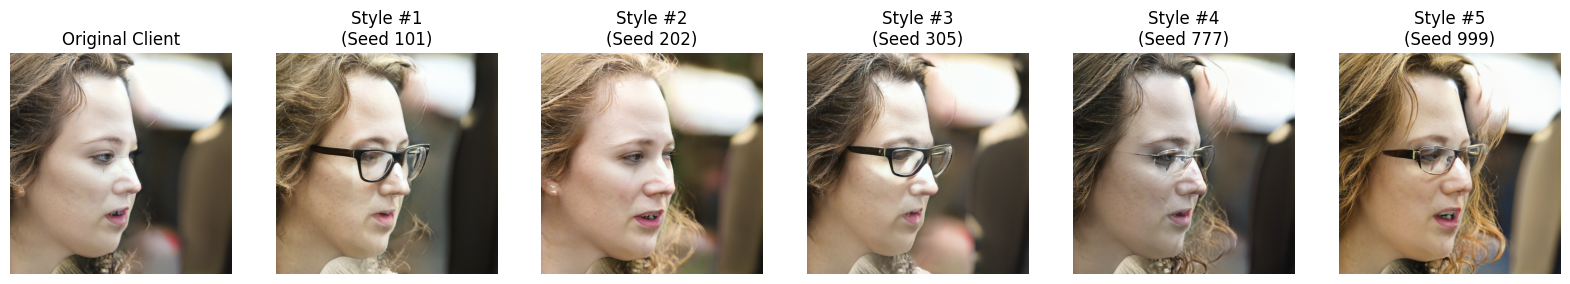

In [11]:
def experiment_virtual_optician(source_seed=200, save_path="experiment_result.png"):
    print("Virtual Optician: Generating different styles for one client...")
    
    torch.manual_seed(source_seed)
    z = torch.randn([1, G_ema.z_dim]).to(device)
    w_source = G_ema.mapping(z, None)[:, 0, :]
    
    edit_seeds = [101, 202, 305, 777, 999]
    results = []
    
    for seed in edit_seeds:
        torch.manual_seed(seed) 
        w_out = sde_edit(w_source, target_label=1, start_step=200, guidance_scale=2.0)
        results.append(w_out)

    def to_img(w):
        w_full = w.unsqueeze(1).repeat(1, 18, 1)
        img = G_ema.synthesis(w_full, noise_mode='const')
        return (img.permute(0, 2, 3, 1) * 127.5 + 128).clamp(0, 255).to(torch.uint8).cpu().numpy()[0]

    fig, ax = plt.subplots(1, len(results) + 1, figsize=(20, 4))
    
    ax[0].imshow(to_img(w_source))
    ax[0].set_title("Original Client")
    ax[0].axis('off')
    
    for i, (res, seed) in enumerate(zip(results, edit_seeds)):
        ax[i+1].imshow(to_img(res))
        ax[i+1].set_title(f"Style #{i+1}\n(Seed {seed})")
        ax[i+1].axis('off')

    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    print(f"Image saved to: {save_path}")
    plt.show()

experiment_virtual_optician(source_seed=200, save_path="results_diffusion/different_glasses.png")

In [12]:
def visualize_edit(seed, target_val, t_start=150, cfg=3.0):
    torch.manual_seed(seed)
    z = torch.randn([1, G_ema.z_dim]).to(device)
    w_source = G_ema.mapping(z, None)[:, 0, :]
    
    w_edited = sde_edit(w_source, target_val, t_start, cfg)
    
    w_source_full = w_source.unsqueeze(1).repeat(1, G_ema.num_ws, 1)
    w_edited_full = w_edited.unsqueeze(1).repeat(1, G_ema.num_ws, 1)
    
    img_orig = G_ema.synthesis(w_source_full, noise_mode='const')
    img_edit = G_ema.synthesis(w_edited_full, noise_mode='const')

    save_single_image(img_orig, f'original_seed{seed}_t{t_start}_cfg{cfg}.png')
    save_single_image(img_edit, f'failure{seed}_t{t_start}_cfg{cfg}.png')
    
    fig, ax = plt.subplots(1, 2, figsize=(10, 5))
    def process(t): return (t[0].permute(1,2,0).cpu().detach() * 0.5 + 0.5).clamp(0,1)
    
    ax[0].imshow(process(img_orig))
    ax[0].set_title(f"Original (Seed {seed})")
    ax[0].axis('off')
    
    ax[1].imshow(process(img_edit))
    ax[1].set_title(f"Edited: {ATTR_NAME}={target_val}\n(t={t_start}, cfg={cfg})")
    ax[1].axis('off')
    plt.show()

Experiment 1: Standard Edit
Saved: original_seed450_t100_cfg5.0.png
Saved: failure450_t100_cfg5.0.png


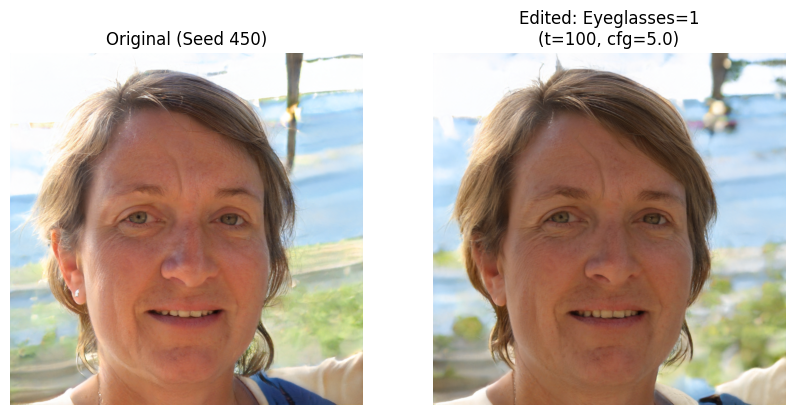

Experiment 2: Noise Level Analysis (t=50 vs t=300)
Saved: original_seed450_t50_cfg3.0.png
Saved: failure450_t50_cfg3.0.png


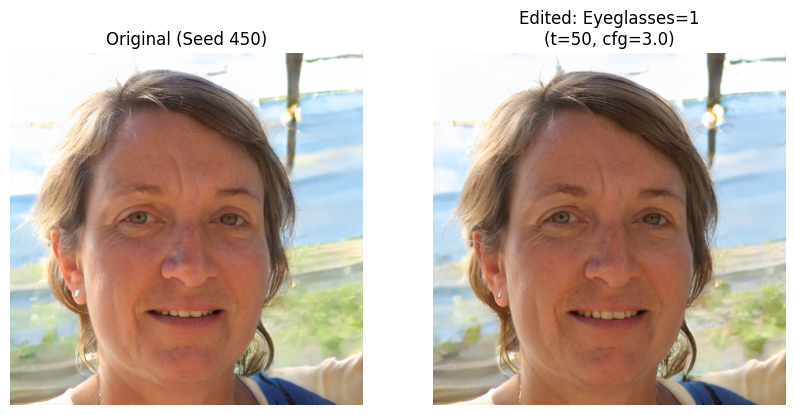

Saved: original_seed450_t300_cfg3.0.png
Saved: failure450_t300_cfg3.0.png


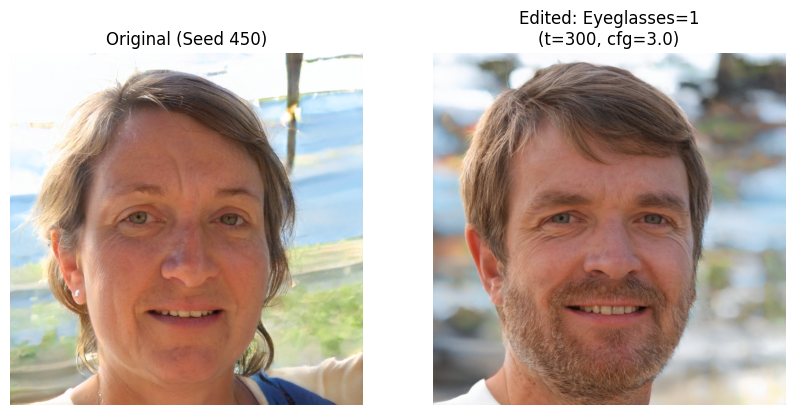

Experiment 3: Guidance Scale Analysis (CFG=2 vs CFG=10)
Saved: original_seed450_t150_cfg2.0.png
Saved: failure450_t150_cfg2.0.png


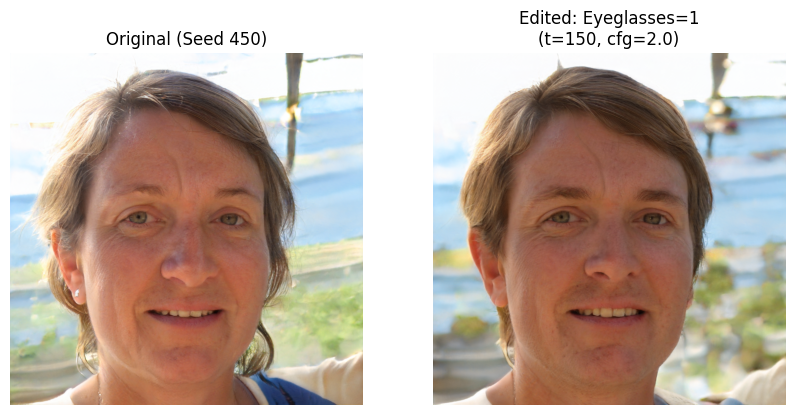

Saved: original_seed450_t150_cfg10.0.png
Saved: failure450_t150_cfg10.0.png


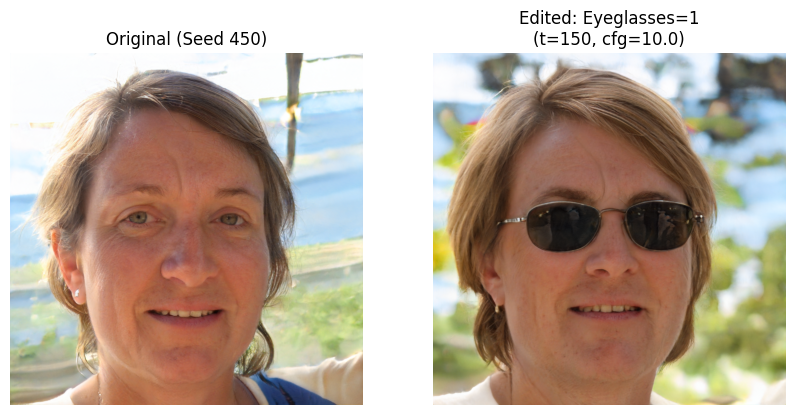

Extreme: t= 500 and CFG=15
Saved: original_seed450_t500_cfg15.0.png
Saved: failure450_t500_cfg15.0.png


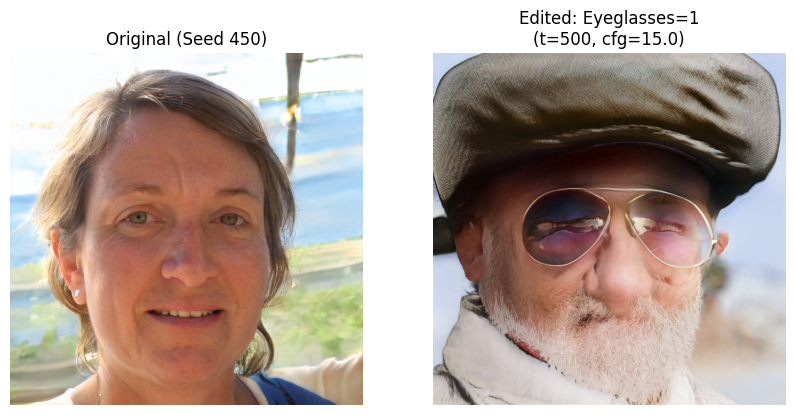

In [13]:
SEED = 450

print("Experiment 1: Standard Edit")
visualize_edit(seed=SEED, target_val=1, t_start=100, cfg=5.0)

print("Experiment 2: Noise Level Analysis (t=50 vs t=300)")
visualize_edit(seed=SEED, target_val=1, t_start=50, cfg=3.0)
visualize_edit(seed=SEED, target_val=1, t_start=300, cfg=3.0)

print("Experiment 3: Guidance Scale Analysis (CFG=2 vs CFG=10)")
visualize_edit(seed=SEED, target_val=1, t_start=150, cfg=2.0)
visualize_edit(seed=SEED, target_val=1, t_start=150, cfg=10.0)

print("Extreme: t=500 and CFG=15")
visualize_edit(seed=SEED, target_val=1, t_start=500, cfg=15.0)

Processing t=50, cfg=2.0...
Processing t=50, cfg=3.5...
Processing t=50, cfg=5.0...
Processing t=50, cfg=7.0...
Processing t=50, cfg=10.0...
Processing t=100, cfg=2.0...
Processing t=100, cfg=3.5...
Processing t=100, cfg=5.0...
Processing t=100, cfg=7.0...
Processing t=100, cfg=10.0...
Processing t=150, cfg=2.0...
Processing t=150, cfg=3.5...
Processing t=150, cfg=5.0...
Processing t=150, cfg=7.0...
Processing t=150, cfg=10.0...
Processing t=200, cfg=2.0...
Processing t=200, cfg=3.5...
Processing t=200, cfg=5.0...
Processing t=200, cfg=7.0...
Processing t=200, cfg=10.0...
Processing t=300, cfg=2.0...
Processing t=300, cfg=3.5...
Processing t=300, cfg=5.0...
Processing t=300, cfg=7.0...
Processing t=300, cfg=10.0...
 Image saved to: results_diffusion/grid_search_glasses.png


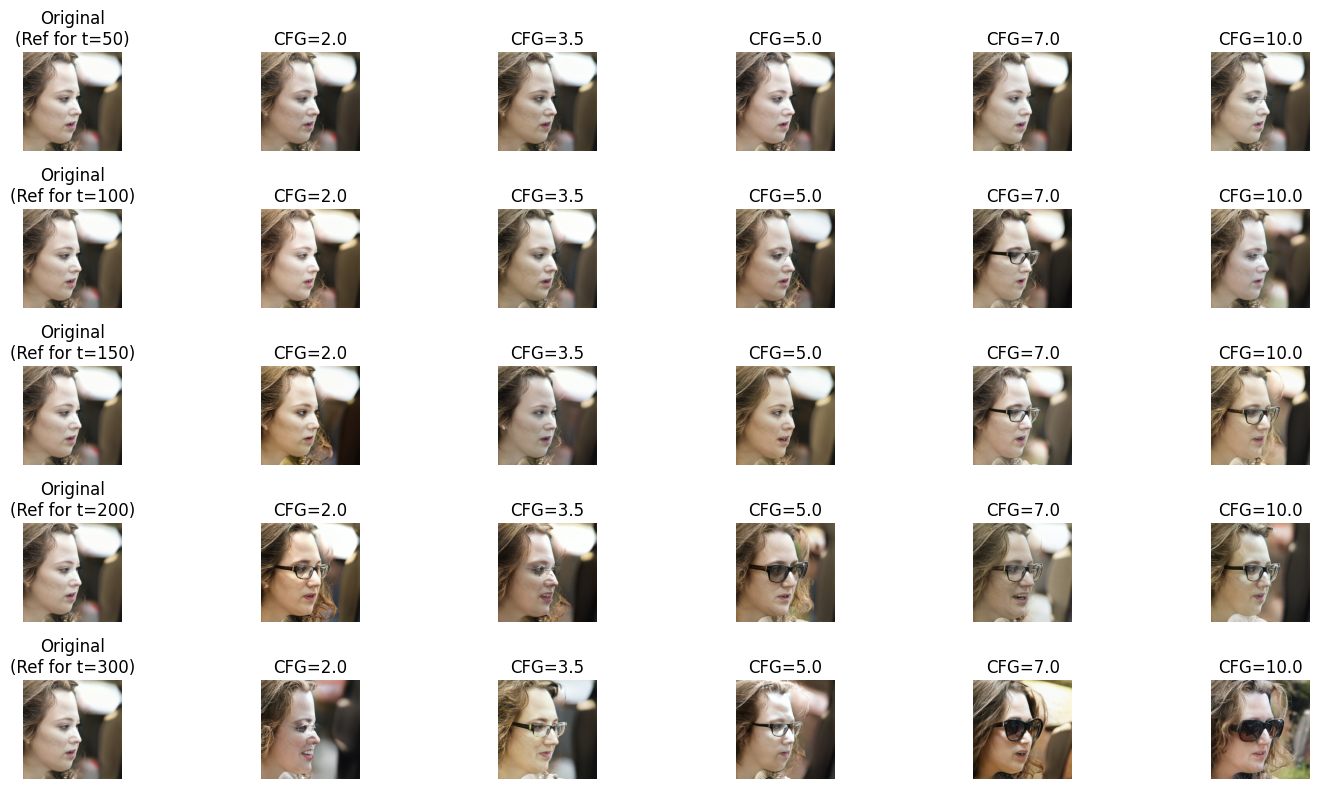

In [14]:
def grid_search_edit(seed, save_path="experiment_result.png"):
    torch.manual_seed(seed)
    z = torch.randn([1, G_ema.z_dim]).to(device)
    w_source = G_ema.mapping(z, None)[:, 0, :]
    
    t_values = [50, 100, 150, 200, 300] 
    cfg_values = [2.0, 3.5, 5.0, 7.0, 10.0]
    
    fig, axes = plt.subplots(len(t_values), len(cfg_values) + 1, figsize=(15, 8))
    
    w_source_full = w_source.unsqueeze(1).repeat(1, G_ema.num_ws, 1)
    img_orig = G_ema.synthesis(w_source_full, noise_mode='const')
    img_orig_np = (img_orig[0].permute(1,2,0).cpu().detach() * 0.5 + 0.5).clamp(0,1)
    
    for i, t in enumerate(t_values):
        axes[i, 0].imshow(img_orig_np)
        axes[i, 0].set_title(f"Original\n(Ref for t={t})")
        axes[i, 0].axis('off')
        
        for j, cfg in enumerate(cfg_values):
            print(f"Processing t={t}, cfg={cfg}...")
            w_edited = sde_edit(
                w_source, 
                target_label=1, 
                start_step=t, 
                guidance_scale=cfg 
            )
            
            w_edited_full = w_edited.unsqueeze(1).repeat(1, G_ema.num_ws, 1)
            img_edit = G_ema.synthesis(w_edited_full, noise_mode='const')
            img_edit_np = (img_edit[0].permute(1,2,0).cpu().detach() * 0.5 + 0.5).clamp(0,1)
            
            axes[i, j+1].imshow(img_edit_np)
            axes[i, j+1].set_title(f"CFG={cfg}")
            axes[i, j+1].axis('off')

    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    print(f"Image saved to: {save_path}")
    plt.show()

grid_search_edit(seed=200, save_path="results_diffusion/grid_search_glasses.png")

# Section 8 — Save Results

In [15]:
SEED = 570
torch.manual_seed(SEED)

z = torch.randn([1, G_ema.z_dim]).to(device)
w_source = G_ema.mapping(z, None)[:, 0, :]

w_source_full = w_source.unsqueeze(1).repeat(1, G_ema.num_ws, 1)
img_orig = G_ema.synthesis(w_source_full, noise_mode='const')
save_single_image(img_orig, f'original_seed{SEED}.png')

# Part A: Noise Level Analysis
fixed_cfg = 7.0
t_values = [50, 100, 150, 200, 300]

for t in t_values:
    w_edit = sde_edit(
        w_source, 
        target_label=1,
        start_step=t, 
        guidance_scale=fixed_cfg          
    )
    w_edit_full = w_edit.unsqueeze(1).repeat(1, G_ema.num_ws, 1)
    img_edit = G_ema.synthesis(w_edit_full, noise_mode='const')
    save_single_image(img_edit, f'exp{SEED}_noise_t{t}_cfg{fixed_cfg}.png')

Saved: original_seed570.png
--------------------
Running Part A: Noise Levels...
Processing t=50...
Saved: exp570_noise_t50_cfg7.0.png
Processing t=100...
Saved: exp570_noise_t100_cfg7.0.png
Processing t=150...
Saved: exp570_noise_t150_cfg7.0.png
Processing t=200...
Saved: exp570_noise_t200_cfg7.0.png
Processing t=300...
Saved: exp570_noise_t300_cfg7.0.png


In [16]:
# Part B: Guidance Scale Analysis
fixed_t = 100
cfg_values = [2.0, 3.5, 5.0, 7.0, 10.0]

for cfg in cfg_values:
    w_edit = sde_edit(
        w_source, 
        target_label=1, 
        start_step=fixed_t, 
        guidance_scale=cfg
    )
    w_edit_full = w_edit.unsqueeze(1).repeat(1, G_ema.num_ws, 1)
    img_edit = G_ema.synthesis(w_edit_full, noise_mode='const')
    save_single_image(img_edit, f'exp{SEED}_guidance_t{fixed_t}_cfg{cfg}.png')

--------------------
Running Part B: Guidance Scales...
Processing CFG=2.0...
Saved: exp570_guidance_t100_cfg2.0.png
Processing CFG=3.5...
Saved: exp570_guidance_t100_cfg3.5.png
Processing CFG=5.0...
Saved: exp570_guidance_t100_cfg5.0.png
Processing CFG=7.0...
Saved: exp570_guidance_t100_cfg7.0.png
Processing CFG=10.0...
Saved: exp570_guidance_t100_cfg10.0.png


In [17]:
!zip -r results_diffusion.zip results_diffusion

------------------------------
Zipping files for easy download...
updating: results_diffusion/ (stored 0%)
updating: results_diffusion/exp200_guidance_t150_cfg5.0.png (deflated 0%)
updating: results_diffusion/exp200_guidance_t150_cfg2.0.png (deflated 0%)
updating: results_diffusion/exp200_noise_t150_cfg3.0.png (deflated 0%)
updating: results_diffusion/exp200_noise_t200_cfg3.0.png (deflated 0%)
updating: results_diffusion/exp200_noise_t100_cfg3.0.png (deflated 0%)
updating: results_diffusion/exp200_guidance_t150_cfg10.0.png (deflated 0%)
updating: results_diffusion/exp200_noise_t300_cfg3.0.png (deflated 0%)
updating: results_diffusion/exp200_guidance_t150_cfg7.5.png (deflated 0%)
updating: results_diffusion/exp200_noise_t50_cfg3.0.png (deflated 0%)
updating: results_diffusion/exp200_guidance_t150_cfg3.5.png (deflated 0%)
updating: results_diffusion/original_seed200.png (deflated 0%)
updating: results_diffusion/exp570_guidance_t150_cfg10.0.png (deflated 0%)
updating: results_diffusion/ex